Valeria Sarahi Reyes Mendoza 2164878

Marina Maldonado Montemayor 2276151

Cesar Said Herrera Velazquez 2204661

Manuel Benavides Herrera 2276359

Ximena Maria Mejia Zuñiga 2208778

Ejercicio 1.1.- Limpieza y Manipulación con Pandas

Objetivo: Cargar los datos, entender su estructura y realizar filtrados básicos.

**Lógica**: Se carga el dataset de vino tinto desde UCI, se inspeccionan sus primeras filas y estadísticas, se revisan y eliminan valores nulos, se crea la etiqueta binaria is_good y se filtran los vinos con alcohol superior al 11%.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
url_wine = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df_wine = pd.read_csv(url_wine, sep=";")

print("Dataset cargado correctamente")

Dataset cargado correctamente


In [ ]:
display(df_wine.head())
print("\nResumen estadístico:")
display(df_wine.describe())


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_good
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0



Resumen estadístico:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_good
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023,0.135710
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569,0.342587
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000,0.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000,0.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000,0.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1.000000


In [ ]:
print("\nValores nulos por columna:")
print(df_wine.isnull().sum())
print("\nTotal de valores nulos:", df_wine.isnull().sum().sum())



Valores nulos por columna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
is_good                 0
dtype: int64

Total de valores nulos: 0


In [ ]:
df_wine = df_wine.dropna().copy()
df_wine["is_good"] = (df_wine["quality"] > 6).astype(int)

vinos_alcohol = df_wine[df_wine["alcohol"] > 11]
print("\nVinos con alcohol superior al 11%:")
display(vinos_alcohol.head())
print("Cantidad de vinos filtrados:", len(vinos_alcohol))


Vinos con alcohol superior al 11%:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_good
45,4.6,0.52,0.15,2.1,0.054,8.0,65.0,0.9934,3.90,0.56,13.1,4,0
95,4.7,0.60,0.17,2.3,0.058,17.0,106.0,0.9932,3.85,0.60,12.9,6,0
131,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5,0
132,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5,0
142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6,0


Cantidad de vinos filtrados: 408


Valeria Sarahi Reyes Mendoza 2164878

Marina Maldonado Montemayor
2276151

Cesar Said Herrera Velazquez
2204661

Manuel Benavides Herrera 2276359

Ximena Maria Mejia Zuñiga 2208778

Ejercicio 1.2.- Operaciones Matemáticas con NumPy

Objetivo: Convertir los datos a matrices y realizar cálculos de bajo nivel que la IA necesita.

**Lógica**: Se separan las características numéricas del objetivo quality y de la etiqueta creada. Se calculan media y desviación estándar por columna y se aplica la normalización Z-Score. Se evita dividir entre cero en caso de que alguna característica sea constante.

In [ ]:
features_wine = df_wine.drop(columns=["quality", "is_good"])
X = features_wine.to_numpy(dtype=float)

media_wine = np.mean(X, axis=0)
std_wine = np.std(X, axis=0)

print("Matriz X:", X.shape)
print("\nMedia por característica:")
print(pd.Series(media_wine, index=features_wine.columns))

Matriz X: (1599, 11)

Media por característica:
fixed acidity            8.319637
volatile acidity         0.527821
citric acid              0.270976
residual sugar           2.538806
chlorides                0.087467
free sulfur dioxide     15.874922
total sulfur dioxide    46.467792
density                  0.996747
pH                       3.311113
sulphates                0.658149
alcohol                 10.422983
dtype: float64


In [ ]:
print("\nDesviación estándar por característica:")
print(pd.Series(std_wine, index=features_wine.columns))

std_segura = np.where(std_wine == 0, 1, std_wine)
X_zscore = (X - media_wine) / std_segura


Desviación estándar por característica:
fixed acidity            1.740552
volatile acidity         0.179004
citric acid              0.194740
residual sugar           1.409487
chlorides                0.047051
free sulfur dioxide     10.456886
total sulfur dioxide    32.885037
density                  0.001887
pH                       0.154338
sulphates                0.169454
alcohol                  1.065334
dtype: float64


In [ ]:
print("\nMatriz normalizada Z-Score:", X_zscore.shape)
print("Primeras 5 filas normalizadas:")
print(X_zscore[:5])


Matriz normalizada Z-Score: (1599, 11)
Primeras 5 filas normalizadas:
[[-0.52835961  0.96187667 -1.39147228 -0.45321841 -0.24370669 -0.46619252
  -0.37913269  0.55827446  1.28864292 -0.57920652 -0.96024611]
 [-0.29854743  1.96744245 -1.39147228  0.04341614  0.2238752   0.87263823
   0.62436323  0.02826077 -0.7199333   0.1289504  -0.58477711]
 [-0.29854743  1.29706527 -1.18607043 -0.16942723  0.09635286 -0.08366945
   0.22904665  0.13426351 -0.33117661 -0.04808883 -0.58477711]
 [ 1.65485608 -1.38444349  1.4841536  -0.45321841 -0.26496041  0.10759209
   0.41150046  0.6642772  -0.97910442 -0.46118037 -0.58477711]
 [-0.52835961  0.96187667 -1.39147228 -0.45321841 -0.24370669 -0.46619252
  -0.37913269  0.55827446  1.28864292 -0.57920652 -0.96024611]]


Valeria Sarahi Reyes Mendoza 2164878

Marina Maldonado Montemayor
2276151

Cesar Said Herrera Velazquez
2204661

Manuel Benavides Herrera 2276359

Ximena Maria Mejia Zuñiga 2208778

Ejercicio 1.3.- Visualización de Insights con Matplotlib

Objetivo: Comunicar visualmente las correlaciones y distribuciones de los datos.

**Lógica**: Se genera un histograma para observar la distribución del alcohol, un diagrama de dispersión entre acidez fija y pH, y un boxplot para comparar alcohol entre niveles de calidad.

/tmp/ipykernel_692/3874995524.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot(datos_box, labels=calidades)


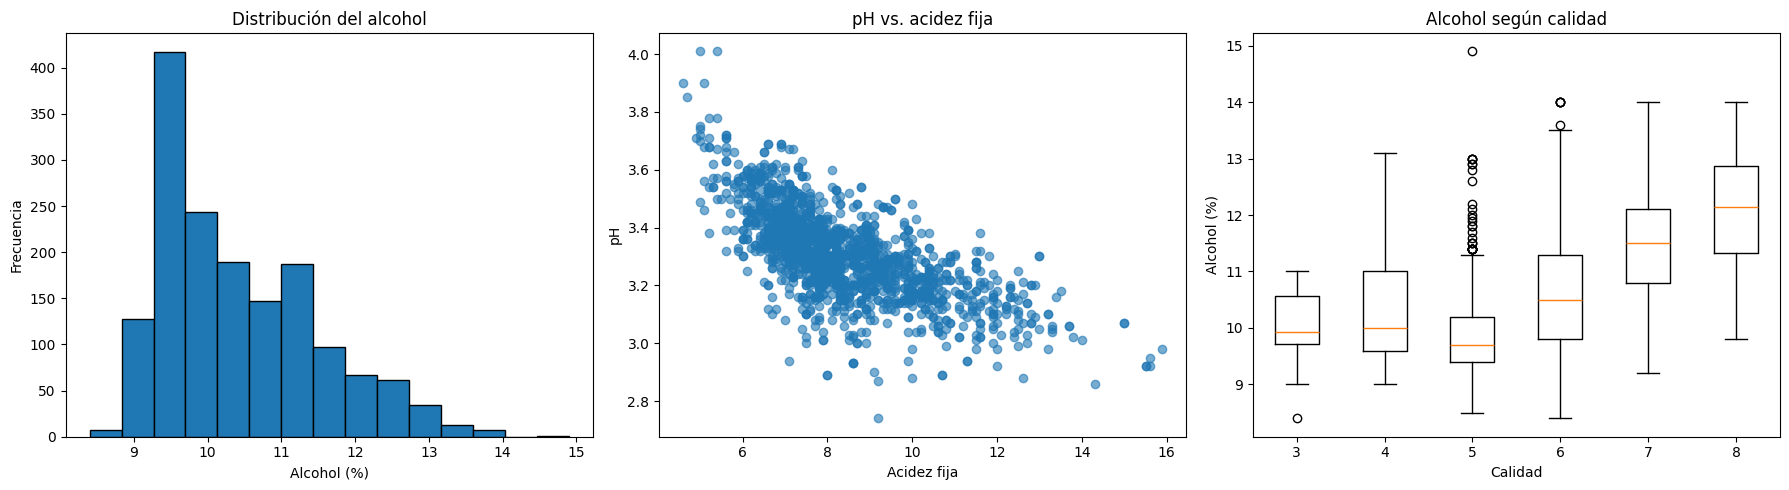

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(df_wine["alcohol"], bins=15, edgecolor="black")
axes[0].set_title("Distribución del alcohol")
axes[0].set_xlabel("Alcohol (%)")
axes[0].set_ylabel("Frecuencia")

axes[1].scatter(df_wine["fixed acidity"], df_wine["pH"], alpha=0.6)
axes[1].set_title("pH vs. acidez fija")
axes[1].set_xlabel("Acidez fija")
axes[1].set_ylabel("pH")

calidades = sorted(df_wine["quality"].unique())
datos_box = [df_wine.loc[df_wine["quality"] == q, "alcohol"] for q in calidades]
axes[2].boxplot(datos_box, labels=calidades)
axes[2].set_title("Alcohol según calidad")
axes[2].set_xlabel("Calidad")
axes[2].set_ylabel("Alcohol (%)")

plt.tight_layout()
plt.show()

Valeria Sarahi Reyes Mendoza 2164878

Marina Maldonado Montemayor
2276151

Cesar Said Herrera Velazquez
2204661

Manuel Benavides Herrera 2276359

Ximena Maria Mejia Zuñiga 2208778

Ejercicio 2.1.- Análisis Exploratorio con Pandas

Objetivo: Limpieza de datos reales (que suelen venir con errores o huecos).

**Lógica**: Se carga el dataset, se cuentan filas con datos faltantes y se eliminan registros sin medidas críticas. Después se calcula la masa promedio por especie e isla y se segmentan los Gentoo de más de 5000 g.

In [ ]:
url_penguins = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df_penguins = pd.read_csv(url_penguins)

print("Dataset cargado correctamente")
display(df_penguins.head())


Dataset cargado correctamente


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [ ]:
filas_con_nan = df_penguins.isna().any(axis=1).sum()
print("\nFilas con al menos un NaN:", filas_con_nan)
print("\nNulos por columna:")
print(df_penguins.isna().sum())

df_penguins_clean = df_penguins.dropna(
    subset=["body_mass_g", "bill_length_mm", "bill_depth_mm"]
).copy()


Filas con al menos un NaN: 11

Nulos por columna:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


In [ ]:
print("\nFilas después de eliminar datos críticos faltantes:", len(df_penguins_clean))

promedio_masa = df_penguins_clean.groupby(
    ["species", "island"], as_index=False
)["body_mass_g"].mean().rename(columns={"body_mass_g": "average_body_mass_g"})
display(promedio_masa)

gentoo_pesados = df_penguins_clean[
    (df_penguins_clean["species"] == "Gentoo") &
    (df_penguins_clean["body_mass_g"] > 5000)
]



Filas después de eliminar datos críticos faltantes: 342


,species,island,average_body_mass_g
0,Adelie,Biscoe,3709.659091
1,Adelie,Dream,3688.392857
2,Adelie,Torgersen,3706.372549
3,Chinstrap,Dream,3733.088235
4,Gentoo,Biscoe,5076.016260


In [ ]:
print("\nGentoo con masa corporal superior a 5000 g:")
display(gentoo_pesados)


Gentoo con masa corporal superior a 5000 g:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
221,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,MALE
223,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,MALE
224,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,MALE
227,Gentoo,Biscoe,46.7,15.3,219.0,5200.0,MALE
229,Gentoo,Biscoe,46.8,15.4,215.0,5150.0,MALE
...,...,...,...,...,...,...,...
335,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,MALE
337,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,MALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


Valeria Sarahi Reyes Mendoza 2164878

Marina Maldonado Montemayor
2276151

Cesar Said Herrera Velazquez
2204661

Manuel Benavides Herrera 2276359

Ximena Maria Mejia Zuñiga 2208778

Ejercicio 2.2.- Procesamiento de Señales con NumPy

Objetivo: Manipulación de dimensiones y cálculos estadísticos rápidos.

**Lógica**: Se construye una matriz. Se calcula la proporción largo/profundidad, se detectan valores de largo del pico a más de dos desviaciones estándar de la media y se extraen las filas de posiciones pares

In [ ]:
pico = df_penguins_clean[["bill_length_mm", "bill_depth_mm"]].to_numpy(dtype=float)
print("Matriz de medidas del pico (N x 2):", pico.shape)

proporcion_pico = pico[:, 0] / pico[:, 1]
print("\nPrimeras 10 proporciones largo/profundidad:")
print(proporcion_pico[:10])

Matriz de medidas del pico (N x 2): (342, 2)

Primeras 10 proporciones largo/profundidad:
[2.09090909 2.27011494 2.23888889 1.9015544  1.90776699 2.18539326
 2.         1.8839779  2.07920792 2.21052632]


In [ ]:
largo_pico = pico[:, 0]
media_largo = np.mean(largo_pico)
std_largo = np.std(largo_pico)

mascara_outliers = np.abs(largo_pico - media_largo) > 2 * std_largo
indices_outliers = np.where(mascara_outliers)[0]

print("\nMedia del largo del pico:", media_largo)
print("Desviación estándar:", std_largo)
print("Índices de posibles outliers:", indices_outliers)


Media del largo del pico: 43.9219298245614
Desviación estándar: 5.4515960231618195
Índices de posibles outliers: [141 168 214 252 320 334]


In [ ]:
display(df_penguins_clean.iloc[indices_outliers])

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
142,Adelie,Dream,32.1,15.5,188.0,3050.0,FEMALE
169,Chinstrap,Dream,58.0,17.8,181.0,3700.0,FEMALE
215,Chinstrap,Dream,55.8,19.8,207.0,4000.0,MALE
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,MALE
321,Gentoo,Biscoe,55.9,17.0,228.0,5600.0,MALE
335,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,MALE


In [ ]:
pico_posiciones_pares = pico[::2]
print("\nDatos de posiciones pares:", pico_posiciones_pares.shape)
print(pico_posiciones_pares[:10])


Datos de posiciones pares: (171, 2)
[[39.1 18.7]
 [40.3 18. ]
 [39.3 20.6]
 [39.2 19.6]
 [42.  20.2]
 [37.8 17.3]
 [38.6 21.2]
 [36.6 17.8]
 [42.5 20.7]
 [46.  21.5]]


Valeria Sarahi Reyes Mendoza 2164878

Marina Maldonado Montemayor
2276151

Cesar Said Herrera Velazquez
2204661

Manuel Benavides Herrera 2276359

Ximena Maria Mejia Zuñiga 2208778

Ejercicio 2.3.- Visualización Científica con Matplotlib

Objetivo: Encontrar patrones visuales que separen a las especies.

**Lógica**: Se comparan las tres especies mediante colores distintos. Se señala el pingüino más pesado en el primer gráfico.

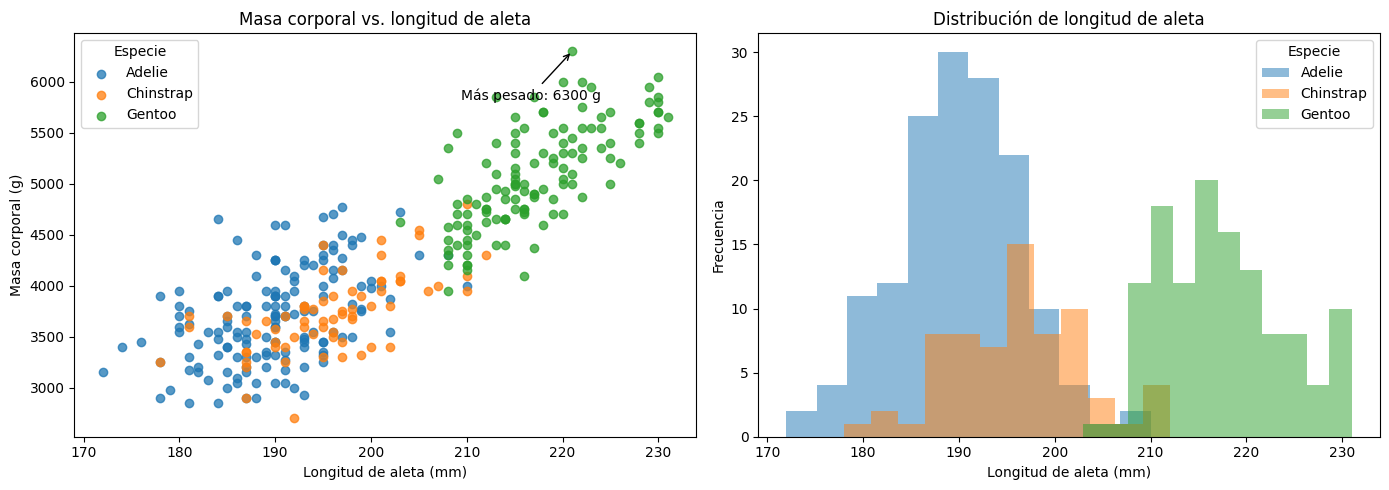

In [ ]:
colores = {
    "Adelie": "tab:blue",
    "Chinstrap": "tab:orange",
    "Gentoo": "tab:green"
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for especie, color in colores.items():
    datos = df_penguins_clean[df_penguins_clean["species"] == especie]
    axes[0].scatter(
        datos["flipper_length_mm"],
        datos["body_mass_g"],
        label=especie,
        color=color,
        alpha=0.75
    )

mas_pesado = df_penguins_clean.loc[df_penguins_clean["body_mass_g"].idxmax()]
axes[0].annotate(
    f"Más pesado: {mas_pesado['body_mass_g']:.0f} g",
    xy=(mas_pesado["flipper_length_mm"], mas_pesado["body_mass_g"]),
    xytext=(-80, -35),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)
axes[0].set_title("Masa corporal vs. longitud de aleta")
axes[0].set_xlabel("Longitud de aleta (mm)")
axes[0].set_ylabel("Masa corporal (g)")
axes[0].legend(title="Especie")

for especie, color in colores.items():
    datos = df_penguins_clean[df_penguins_clean["species"] == especie]
    axes[1].hist(
        datos["flipper_length_mm"],
        bins=12,
        alpha=0.5,
        label=especie,
        color=color
    )

axes[1].set_title("Distribución de longitud de aleta")
axes[1].set_xlabel("Longitud de aleta (mm)")
axes[1].set_ylabel("Frecuencia")
axes[1].legend(title="Especie")

plt.tight_layout()
plt.show()